<h1>8. Gradient Boosting Classifier</h1>
<h3>Step 1: Environment Setup & Library Imports</h3>
<p>Loading essiential python libraries for data processing <b>(pandas, numpy) </b>, visual analytics <b>(matplotlib, seaborn)</b> , and machine learning moodel evaluation <b>(sklearn)</b> , and set consistent visual styling.</p>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score
,confusion_matrix,classification_report,roc_auc_score)
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import GradientBoostingClassifier

import warnings
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
print("All are OK")

All are OK


<h3>Step 2: Dataset Loading & Audit</h3>
<p>We are loading the dataset and finding its <b>shape, data types, missing values, duplicates and target summary</b> (for position).</p>

In [2]:
df = pd.read_csv("../../data/classification/classification.csv")
# Subsample to 10000 rows for computational efficiency
df = df.sample(n=10000, random_state=RANDOM_STATE).reset_index(drop=True)

print("="*35)
print(f"Dataset shape: {df.shape}")
print(f"Columns: {len(df.columns)}")
print(f"\nData types:\n{df.dtypes.value_counts()}")
print(f"\nMissing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print("="*35)

Dataset shape: (10000, 75)
Columns: 75

Data types:
int64      43
float64    18
str        14
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0


<h3>Step 3: Exploratory Data Analysis (EDA)</h3>
<p>In EDA, we are visualizing the target distribution, a correlation heatmap of <b>key performance metrics</b>, feature distributions by position, and two scatter plots which shows feature - target relationship.</p>
<h4>3.1 Target Distribution :</h4>
<p>This target distribution helps in checking whether the dataset is balanced/imbalanced.</p>

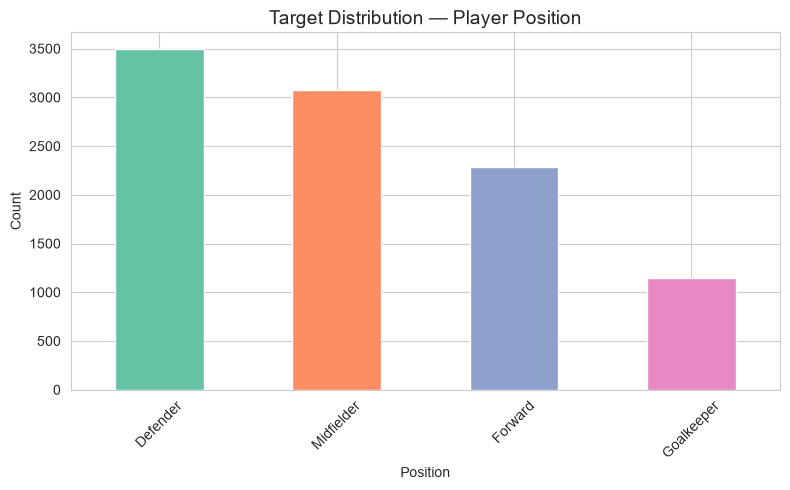

Class proportions:
position
Defender      0.3491
Forward       0.2284
Goalkeeper    0.1151
Midfielder    0.3074
Name: proportion, dtype: float64


In [3]:
# Target distribution
fig, ax = plt.subplots(figsize=(8, 5))
df['position'].value_counts().plot(kind='bar', ax=ax, color=sns.color_palette('Set2'))
ax.set_title('Target Distribution — Player Position', fontsize=14)
ax.set_xlabel('Position')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print("="*35)
print("Class proportions:")
print(df['position'].value_counts(normalize=True).sort_index().round(4))
print("="*35)

<h4>3.2 Correlation Heatmap :</h4>
<p>Correlation among 16 selected key performance features, chosen for their discriminative power over position (offensive, defensive, and physical metrics) 
</p>

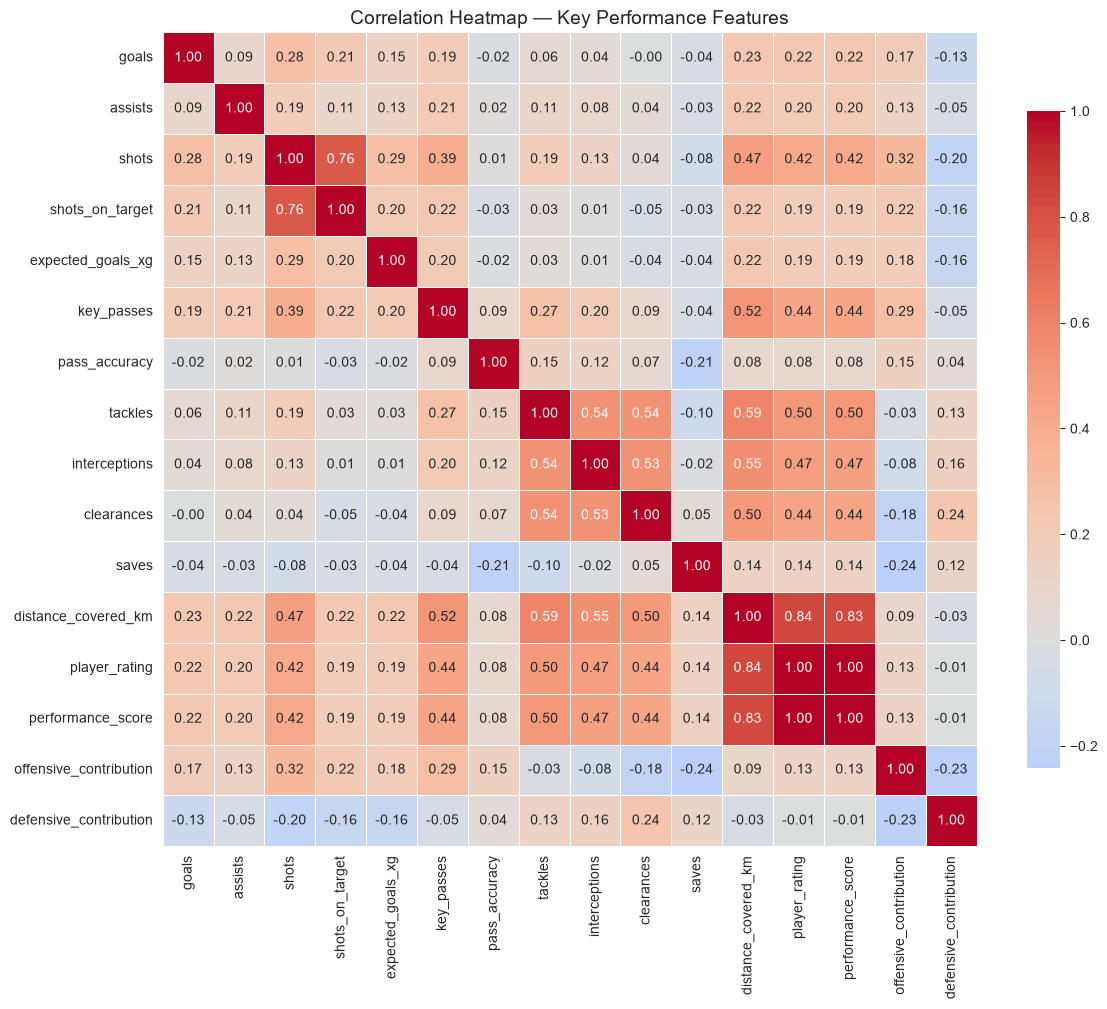

In [4]:
# Correlation heatmap — selected key features only (not all 75 columns)
heatmap_cols = ['goals','assists','shots','shots_on_target','expected_goals_xg',
                'key_passes','pass_accuracy','tackles','interceptions','clearances',
                'saves','distance_covered_km','player_rating','performance_score',
                'offensive_contribution','defensive_contribution']

plt.figure(figsize=(12, 10))
corr_matrix = df[heatmap_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap — Key Performance Features', fontsize=14)
plt.tight_layout()
plt.show()

<h4>3.3 Feature distributions by position :</h4>
<p>Boxplots comparing 6 key metrics across the 4 positions.Goalkeepers dominate saves, defenders dominate clearances . So, this is why position is predictable from performance metrics.
</p>

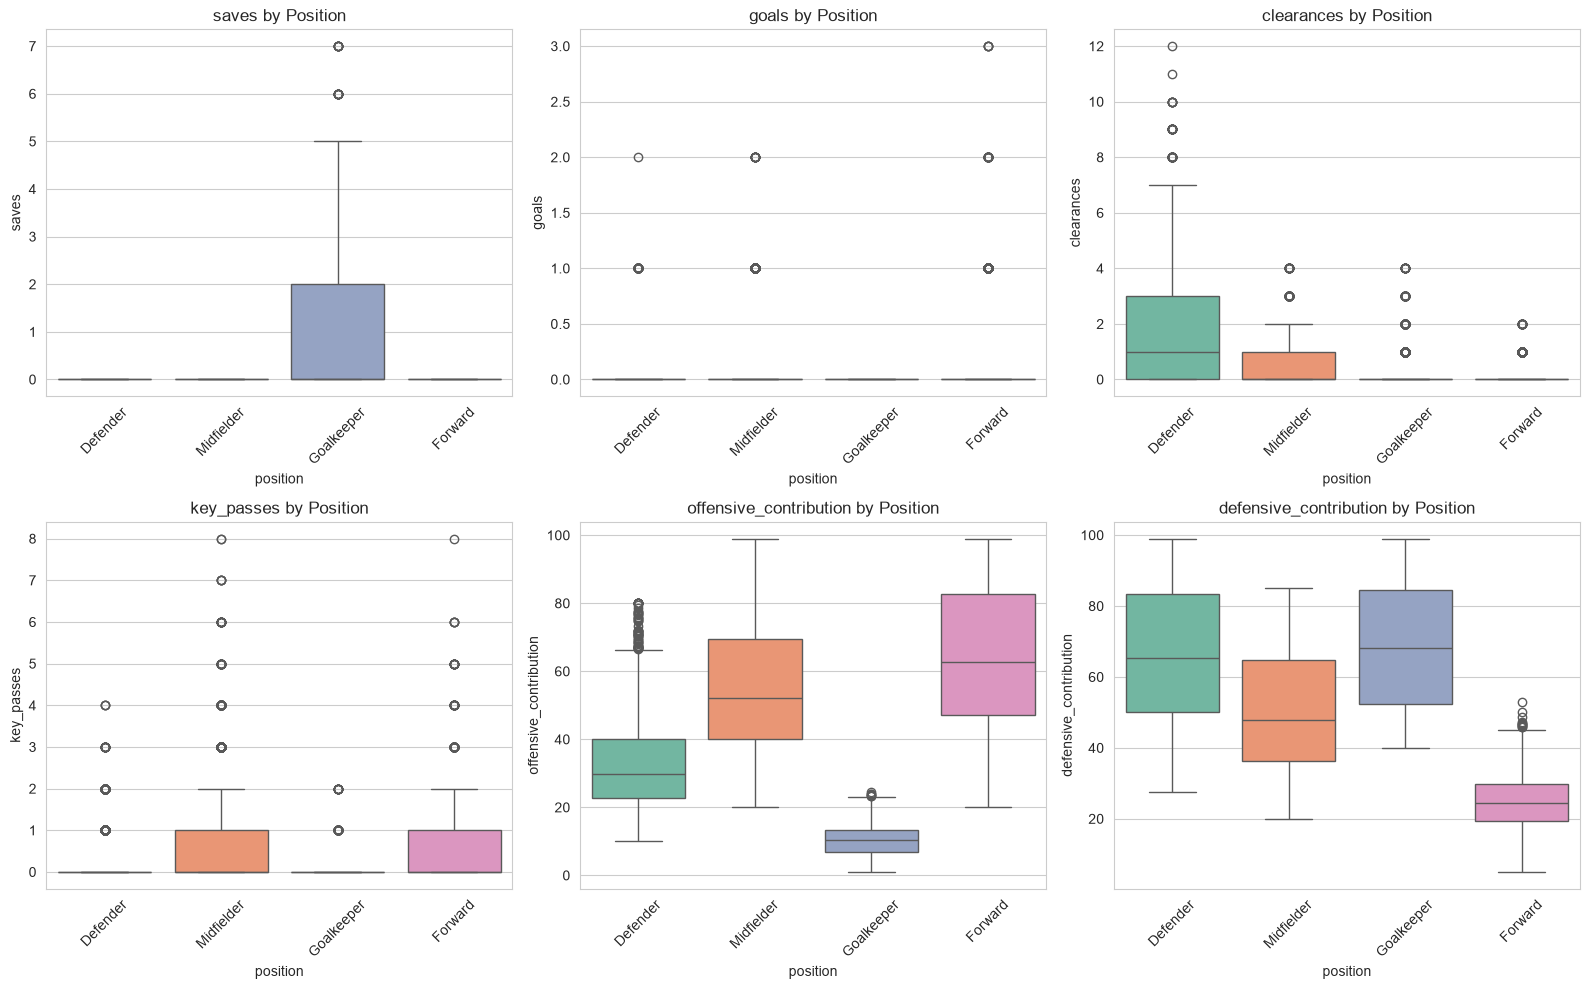

In [5]:
# Feature distributions by position — 6 discriminative features
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
box_features = ['saves','goals','clearances','key_passes',
                'offensive_contribution','defensive_contribution']
for ax, feat in zip(axes.flat, box_features):
    sns.boxplot(data=df, x='position', y=feat, ax=ax, hue='position',
                palette='Set2', legend=False)
    ax.set_title(f'{feat} by Position')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

<h4>3.4 All - feature distribution plots :</h4>
<p>Here distribution of every numeric feature in the dataset happened with help of a histogram plot.
</p>

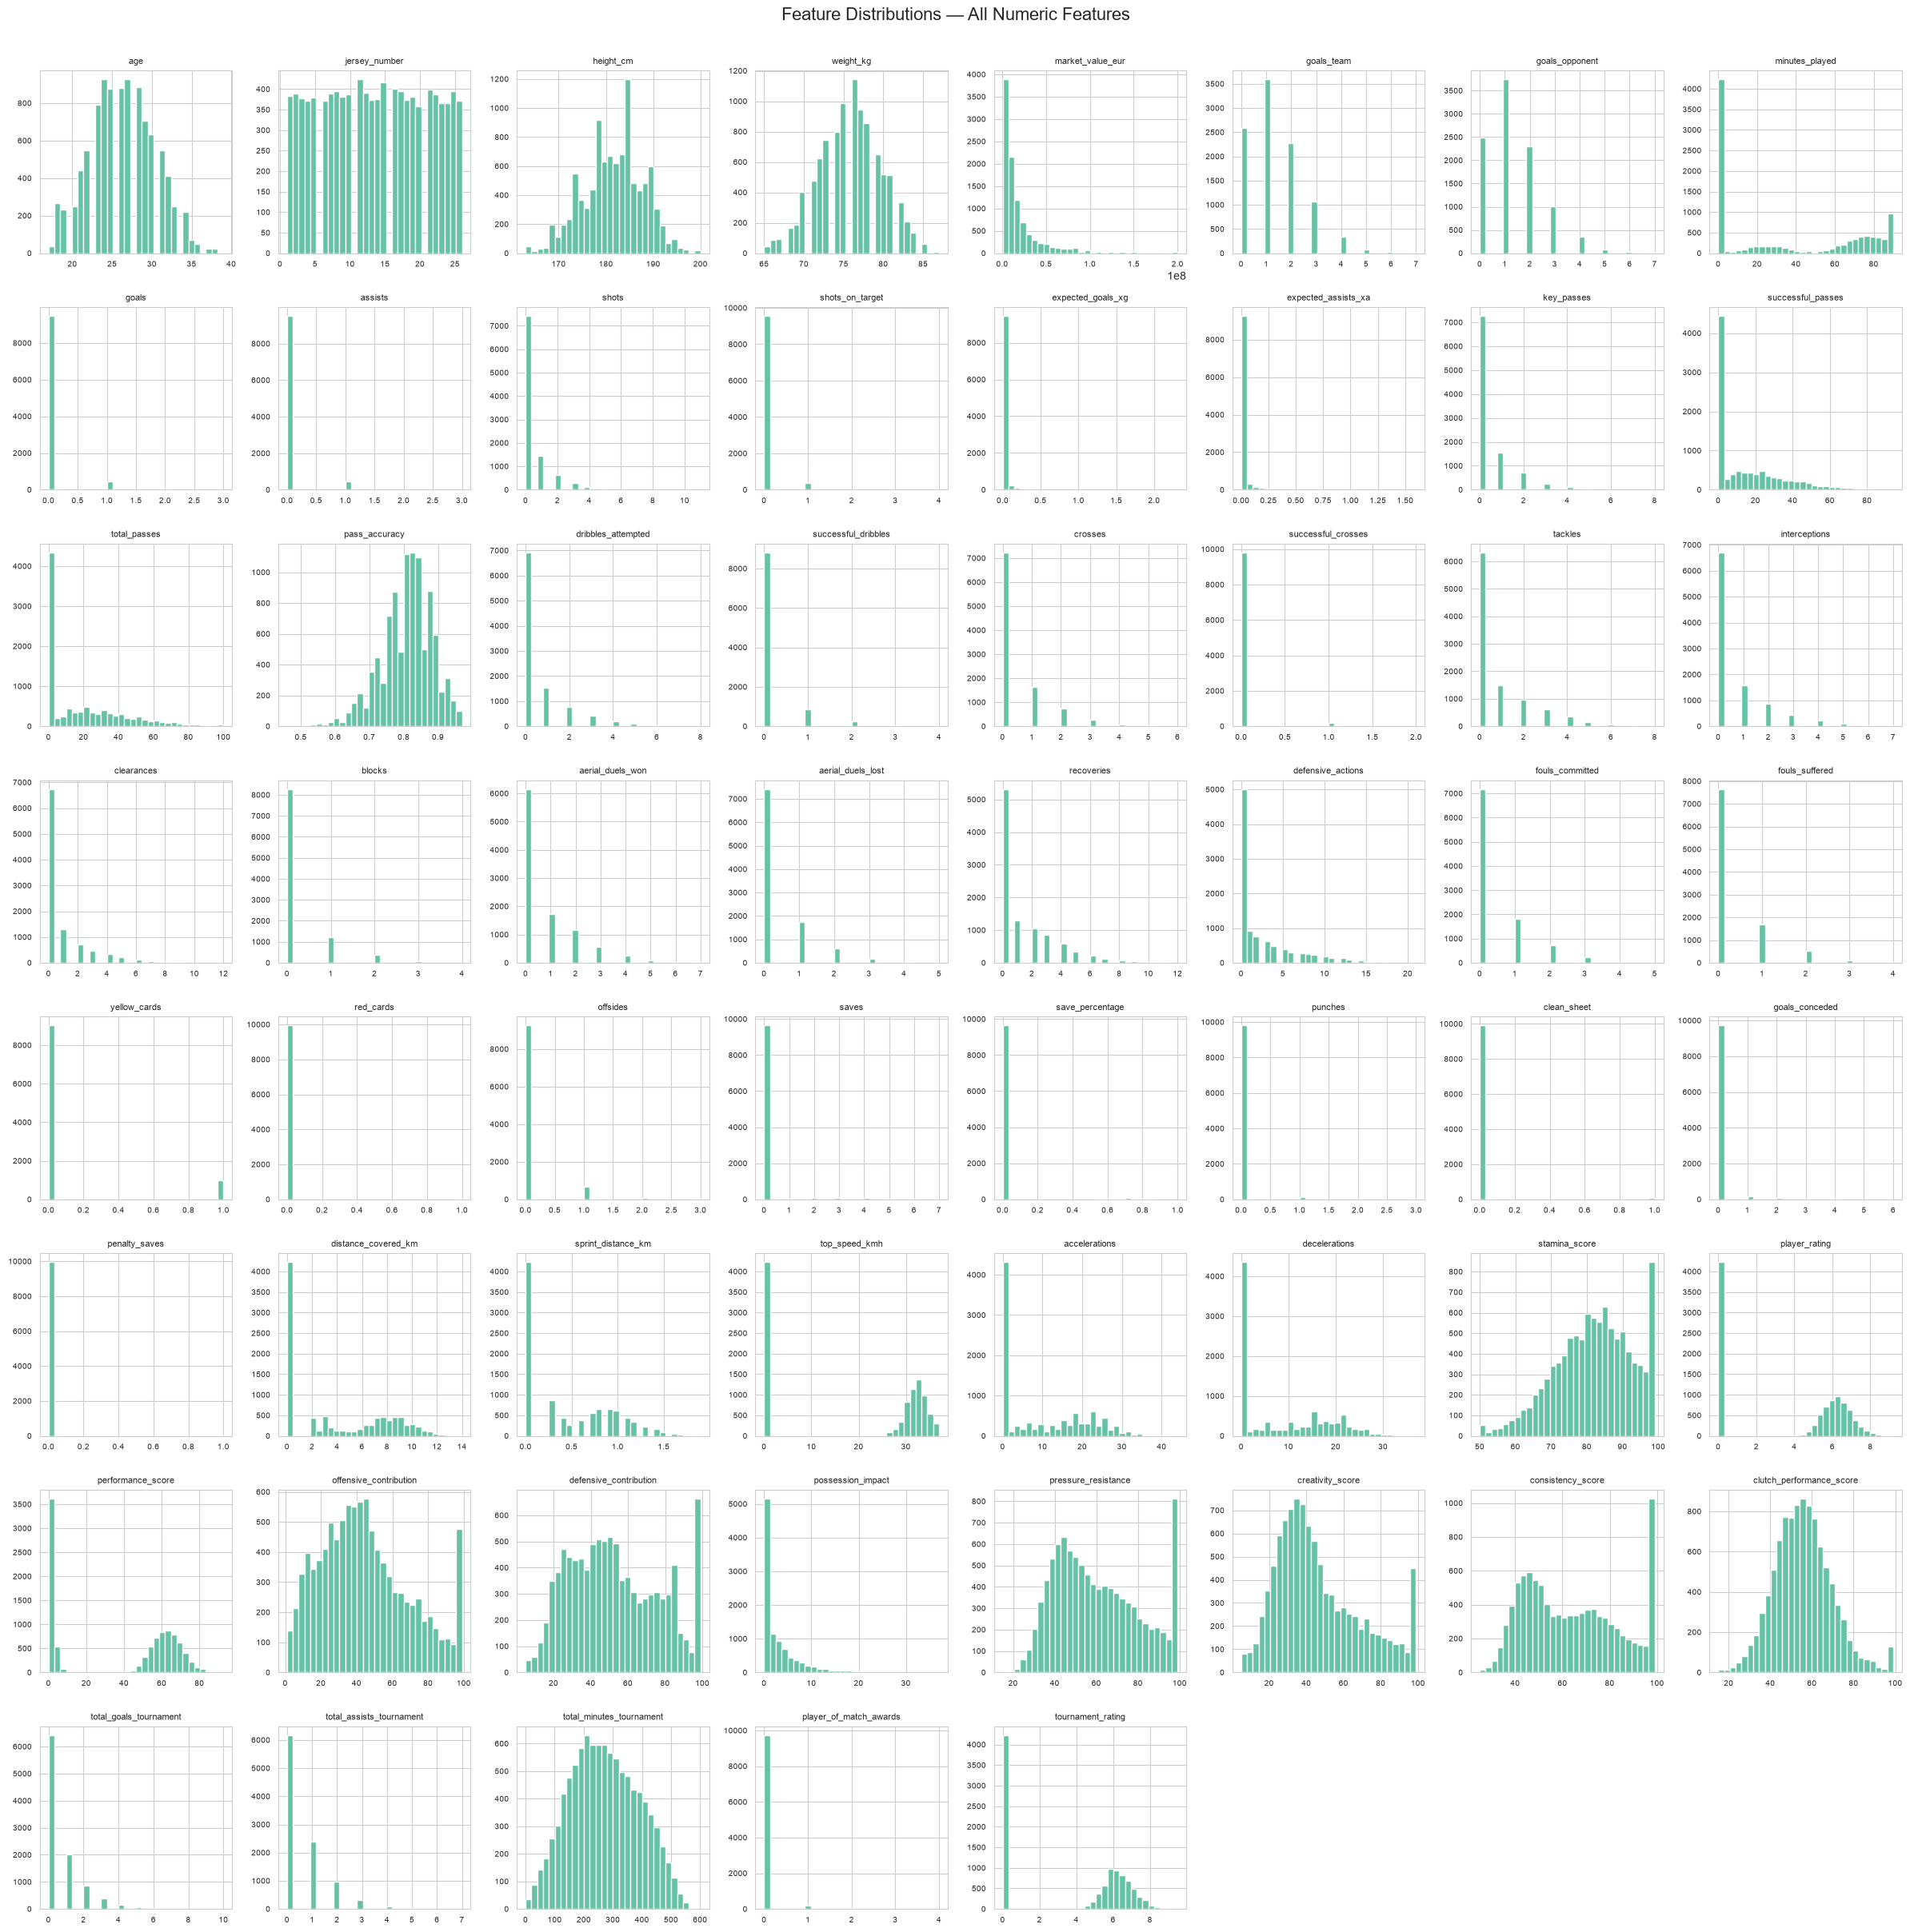

In [6]:
# Distribution plots for ALL numeric features
numeric_cols = df.select_dtypes(include=np.number).columns

n = len(numeric_cols)
ncols = 8
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(24, 3 * nrows))
axes = axes.flat

for ax, col in zip(axes, numeric_cols):
    ax.hist(df[col], bins=30, color=sns.color_palette('Set2')[0], edgecolor='white')
    ax.set_title(col, fontsize=8)
    ax.tick_params(labelsize=7)

# hide empty subplots
for ax in axes[n:]:
    ax.set_visible(False)

plt.suptitle('Feature Distributions — All Numeric Features', fontsize=16, y=1.005)
plt.tight_layout()
plt.show()

<h4>3.5 Feature-target relationships :</h4>
<p>Here scatter plots showing how features relate to the target (position). Forwards cluster high on offensive contribution, defenders high on defensive — the visible separation is why classifiers can learn position from stats.
</p>

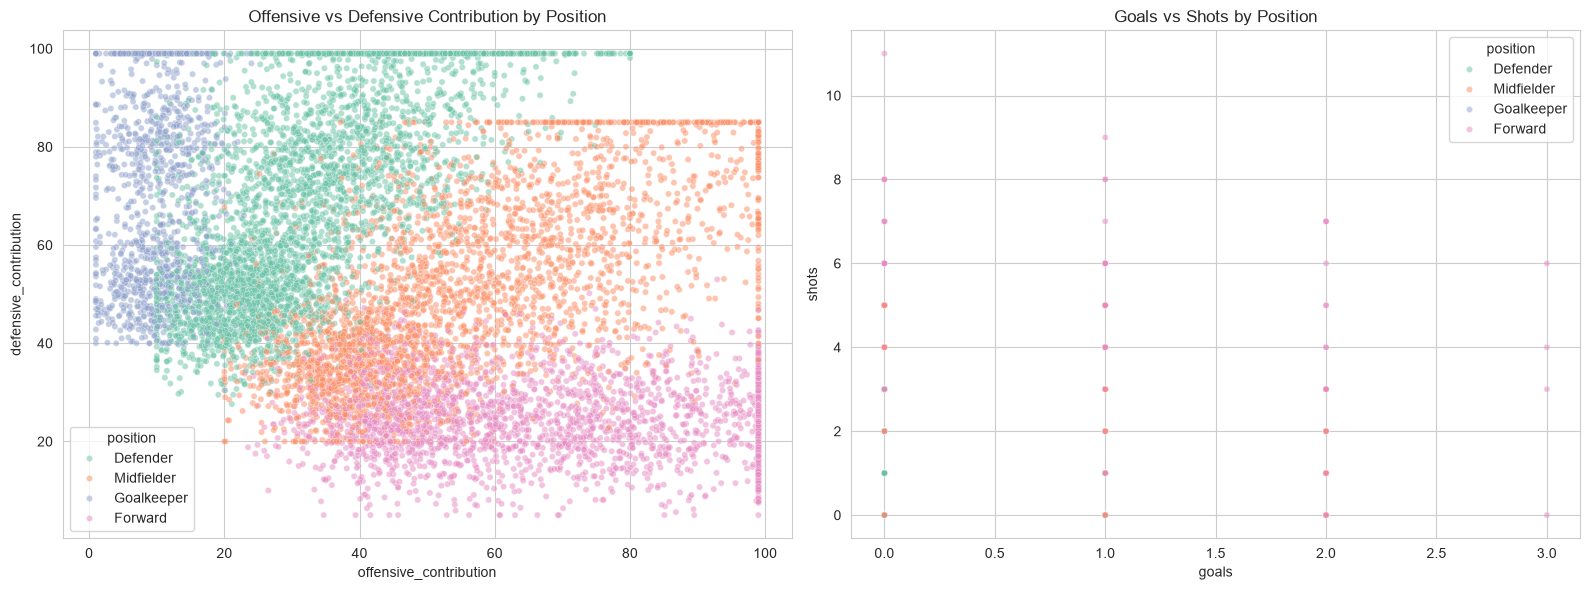

In [7]:
# Scatter plots showing feature-target relationships
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=df, x='offensive_contribution', y='defensive_contribution',
                hue='position', palette='Set2', ax=axes[0], alpha=0.5, s=20)
axes[0].set_title('Offensive vs Defensive Contribution by Position')

sns.scatterplot(data=df, x='goals', y='shots',
                hue='position', palette='Set2', ax=axes[1], alpha=0.5, s=20)
axes[1].set_title('Goals vs Shots by Position')

plt.tight_layout()
plt.show()

<h3>Step 4: Data Cleaning</h3>
<p>The dataset has no missing values and no duplicate samples and capping of outliers took place.</p>

In [8]:
print("="*40)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("="*40)

# Cap extreme outliers on skewed count features at 1st/99th percentiles
cap_cols = ['shots','tackles','defensive_actions','accelerations','decelerations']
for col in cap_cols:
    lower = df[col].quantile(0.01)
    upper = df[col].quantile(0.99)
    df[col] = df[col].clip(lower, upper)
    print(f"  Capped {col}: [{lower}, {upper}]")
print("="*40)

Missing values: 0
Duplicate rows: 0
  Capped shots: [0.0, 4.0]
  Capped tackles: [0.0, 6.0]
  Capped defensive_actions: [0.0, 14.0]
  Capped accelerations: [0.0, 33.0]
  Capped decelerations: [0.0, 29.0]


<h4>4.1 Feature Engineering :</h4>
<p>Here , we created 2 features<br>1. goal contribution = goals + assists<br>2. dual success rate = aerial duels won / (aerial duals won + aerial duals lost + 1)</p>

In [9]:
# Feature 1: combined attacking output
df['goal_contribution'] = df['goals'] + df['assists']

# Feature 2: normalised aerial duel success 
df['duel_success_rate'] = df['aerial_duels_won'] / (df['aerial_duels_won'] + df['aerial_duels_lost'] + 1)

print("="*45)
print("Engineered features — descriptive stats:")
print("="*45)
print(df[['goal_contribution','duel_success_rate']].describe().round(3))
print("="*45)

Engineered features — descriptive stats:
       goal_contribution  duel_success_rate
count          10000.000          10000.000
mean               0.108              0.200
std                0.361              0.270
min                0.000              0.000
25%                0.000              0.000
50%                0.000              0.000
75%                0.000              0.500
max                4.000              0.875


<h3>Step 5: Preprocessing - Encoding,Scaling & Splitting</h3>
<p>
Here, unnecessary columns are removed. Target is label encoded and preferred foot is binary encoded.
The dataset is split into train and test set in 4:1 ratio. StandardScaler is chosen because it centres features at zero with unit variance. 
</p>

In [10]:
# Columns to drop
drop_cols = ['player_id','player_name','nationality','team','jersey_number',
             'club_name','match_id','match_date','stadium','city',
             'opponent_team','tournament_stage','match_result',
             'goals_team','goals_opponent']

df_model = df.drop(columns=drop_cols)

# Encode target
le = LabelEncoder()
df_model['position'] = le.fit_transform(df_model['position'])
print("="*130)
print("Position encoding:", dict(zip(le.classes_, le.transform(le.classes_))))
print("="*130)

# Binary encode preferred_foot
df_model['preferred_foot'] = df_model['preferred_foot'].map({'Left': 0, 'Right': 1})

# Separate features and target
X = df_model.drop(columns=['position'])
y = df_model['position']

# Stratified 80:20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f"\nTrain shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"Train class distribution:\n{y_train.value_counts(normalize=True).sort_index().round(4)}")

# Scale features — fit on train only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"\nScaled train — mean: {X_train_scaled.mean():.4f}, std: {X_train_scaled.std():.4f}")

Position encoding: {'Defender': np.int64(0), 'Forward': np.int64(1), 'Goalkeeper': np.int64(2), 'Midfielder': np.int64(3)}

Train shape: (8000, 61), Test shape: (2000, 61)
Train class distribution:
position
0    0.3491
1    0.2284
2    0.1151
3    0.3074
Name: proportion, dtype: float64

Scaled train — mean: -0.0000, std: 1.0000


<h3>Step 6: Model Training - Gradient Boosting Classifier</h3>
<p>Gradient Boosting builds trees one at a time, each new tree correcting the errors left by the previous ones, and we tune the learning rate and number of trees because they trade off against each other.</p>

In [11]:
# Tune learning_rate and n_estimators
lr_list = [0.1, 0.2]
n_list = [50, 100]
results = []
for lr in lr_list:
    for n_est in n_list:
        gb = GradientBoostingClassifier(learning_rate=lr, n_estimators=n_est,
                                        random_state=RANDOM_STATE)
        gb.fit(X_train_scaled, y_train)
        acc = accuracy_score(y_test, gb.predict(X_test_scaled))
        results.append({'learning_rate': lr, 'n_estimators': n_est, 'accuracy': acc})

res_df = pd.DataFrame(results)
best_row = res_df.loc[res_df['accuracy'].idxmax()]
best_lr_gb, best_n_gb = float(best_row['learning_rate']), int(best_row['n_estimators'])
print(res_df.to_string(index=False))
print(f"\nBest: learning_rate={best_lr_gb}, n_estimators={best_n_gb}, accuracy={best_row['accuracy']:.4f}")

 learning_rate  n_estimators  accuracy
           0.1            50    0.9520
           0.1           100    0.9625
           0.2            50    0.9625
           0.2           100    0.9700

Best: learning_rate=0.2, n_estimators=100, accuracy=0.9700


In [12]:
model = GradientBoostingClassifier(learning_rate=best_lr_gb, n_estimators=best_n_gb,
                                   random_state=RANDOM_STATE)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
print(f"Gradient Boosting trained with learning_rate={best_lr_gb}, n_estimators={best_n_gb}")

Gradient Boosting trained with learning_rate=0.2, n_estimators=100


<h3>Top 15 Feature Important Plot</h3>

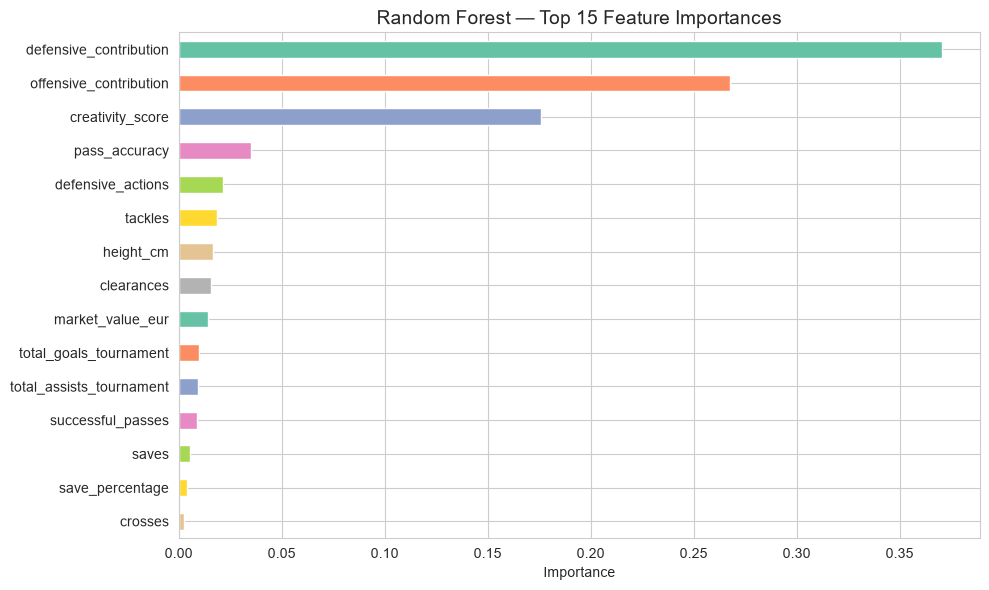

In [13]:
importance = pd.Series(model.feature_importances_, index=X.columns)
top_features = importance.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
top_features.plot(kind='barh', color=sns.color_palette('Set2'))
plt.title('Random Forest — Top 15 Feature Importances', fontsize=14)
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

<h3>Step 7:  Model Evaluation</h3>
<p>All mandatory metrics: Accuracy, Precision, Recall, F1-score (weighted), Confusion Matrix, and ROC-AUC (One-vs-Rest) for multi-class.</p>

  Gradient Boosting — Evaluation Metrics
  Accuracy : 0.9700
  Precision: 0.9700
  Recall   : 0.9700
  F1-score : 0.9700
  ROC-AUC  : 0.9976


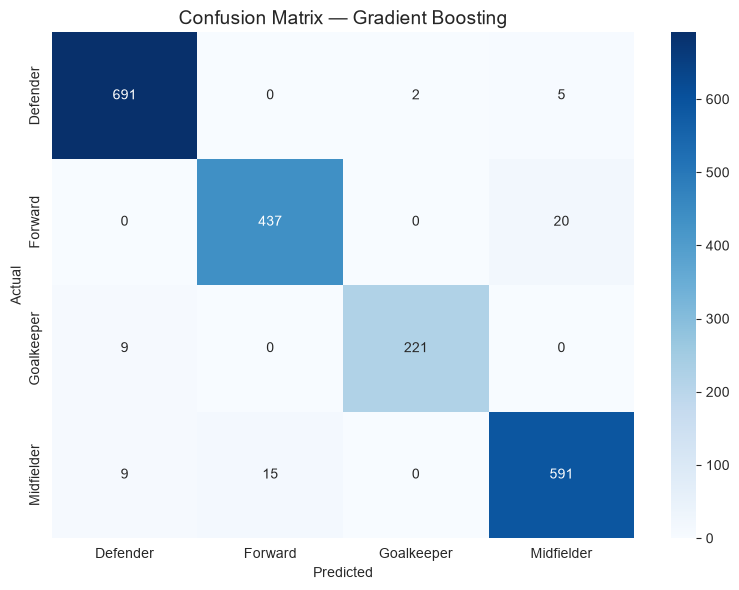


Classification Report:
              precision    recall  f1-score   support

    Defender       0.97      0.99      0.98       698
     Forward       0.97      0.96      0.96       457
  Goalkeeper       0.99      0.96      0.98       230
  Midfielder       0.96      0.96      0.96       615

    accuracy                           0.97      2000
   macro avg       0.97      0.97      0.97      2000
weighted avg       0.97      0.97      0.97      2000



In [14]:
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)

accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall    = recall_score(y_test, y_pred, average='weighted')
f1        = f1_score(y_test, y_pred, average='weighted')
roc_auc   = roc_auc_score(y_test, y_proba, multi_class='ovr', average='weighted')

print("=" * 50)
print(f"  Gradient Boosting — Evaluation Metrics")
print("=" * 50)
print(f"  Accuracy : {accuracy:.4f}")
print(f"  Precision: {precision:.4f}")
print(f"  Recall   : {recall:.4f}")
print(f"  F1-score : {f1:.4f}")
print(f"  ROC-AUC  : {roc_auc:.4f}")
print("=" * 50)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix — Gradient Boosting', fontsize=14)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

In [15]:
# 5-fold cross-validation
cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='accuracy')
print(f"5-Fold CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
print(f"Fold scores: {cv_scores.round(4)}")

5-Fold CV Accuracy: 0.9599 (+/- 0.0059)
Fold scores: [0.9619 0.9656 0.9556 0.9656 0.9506]


In [16]:
import os
import joblib

model_path = "../../models/classification"
os.makedirs(model_path, exist_ok=True)

joblib.dump(model, os.path.join(model_path, "Gradient_Boosting.pkl"))

print("Model exported successfully!")

Model exported successfully!
